# Lab 1 · Chance, repetition, and fair tests

**Level:** Levels 1–2 · **Prerequisites:** L1-02 (probability model), L1-03 (repeat and record), L1-05 (assign a fair comparison)

What you'll learn:

- A probability belongs to a *model*. A relative frequency is a *measurement*, and it can differ from the model.
- Many independent trials usually bring the frequency close to the model probability. This is the law of large numbers. You will also see how big the typical gap is.
- A 95 % band around the probability is about one fixed number of trials. It says nothing about a whole run.
- A coin flip that assigns the treatment balances a hidden trait on average. Letting people choose does not.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pozapas/quantum-causal-ai/blob/main/labs/01-chance.ipynb)

In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from qcai import science as s
from qcai.viz import show

plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

:::{note}
Every random number here comes from a seeded generator. So the notebook gives the same results every time it runs. Coin and dice trials use `qcai.science.trials`, the same engine as the course's interactive lessons.
:::

## 1 · Predict → Run → Explain: a coin and a die

**Predict.** You flip a fair coin 10 times. Will you see exactly 5 heads? After 10,000 flips, will the fraction of heads be exactly one half?

In [3]:
coin10 = s.trials(0.5, 10, seed=42)
coin10k = s.trials(0.5, 10000, seed=42)
die6k = s.trials(1 / 6, 6000, seed=7)          # event = "the die shows a six"

def se(p, n):
    # standard error of a relative frequency under the independent-trials model
    return math.sqrt(p * (1 - p) / n)

for label, r, p in [("10 coin flips", coin10, 0.5), ("10,000 coin flips", coin10k, 0.5),
                    ("6,000 die rolls (six)", die6k, 1 / 6)]:
    gap = r["frequency"] - p
    print(f"{label:24s} hits={r['hits']:5d}  frequency={r['frequency']:.4f}  "
          f"model p={p:.4f}  gap={gap:+.4f}  gap/SE={gap / se(p, r['n']):+.2f}")

10 coin flips            hits=    7  frequency=0.7000  model p=0.5000  gap=+0.2000  gap/SE=+1.26
10,000 coin flips        hits= 4952  frequency=0.4952  model p=0.5000  gap=-0.0048  gap/SE=-0.96
6,000 die rolls (six)    hits=  982  frequency=0.1637  model p=0.1667  gap=-0.0030  gap/SE=-0.62


In [4]:
# The measured frequencies are close to, but not forced to equal, the model probability.
assert coin10k["frequency"] != 0.5 or coin10["frequency"] != 0.5
for r, p in [(coin10k, 0.5), (die6k, 1 / 6)]:
    assert abs(r["frequency"] - p) < 3 * se(p, r["n"]), "frequency outside 3 standard errors"
print("Large-n frequencies are within 3 standard errors of the model probability.")

Large-n frequencies are within 3 standard errors of the model probability.


**Explain.** A probability belongs to the model. The relative frequency (hits ÷ trials) is a measurement [@openstax]. The table prints the gap in units of the standard error $\sqrt{p(1-p)/n}$. With many trials the gap is small *in absolute terms*, because the standard error shrinks like $1/\sqrt{n}$. Yet the count of heads is not pushed toward an exact balance.

## 2 · The law of large numbers, many runs at once

**Predict.** Draw 40 independent runs of 10,000 coin flips. Around $n=10{,}000$, roughly what fraction of the runs should sit inside the band $p \pm 1.96\sqrt{p(1-p)/n}$?

In [5]:
P = 0.5
seeds = [int(x) for x in np.random.default_rng(2024).integers(1, 2**31 - 1, size=40)]
grid = np.unique(np.round(np.logspace(0, 4, 90)).astype(int))      # n = 1 ... 10,000 on a log grid
paths = np.array([np.asarray(s.trials(P, 10000, seed=sd)["trace"])[grid - 1] for sd in seeds])
half = 1.96 * np.sqrt(P * (1 - P) / grid)                          # pointwise 95 % half-width

inside = np.abs(paths - P) <= half
coverage_final = inside[:, -1].mean()
use = grid >= 30                                                   # normal approximation is reasonable here
coverage_pointwise = inside[:, use].mean()
ever_out = (~inside[:, use]).any(axis=1).mean()
print(f"runs inside the band at n=10,000:            {coverage_final:.3f}")
print(f"average pointwise coverage over n >= 30:     {coverage_pointwise:.3f}")
print(f"runs that leave the band at least once (n>=30): {ever_out:.3f}")

runs inside the band at n=10,000:            1.000
average pointwise coverage over n >= 30:     0.960
runs that leave the band at least once (n>=30): 0.400


In [6]:
assert coverage_final >= 0.85
assert 0.88 <= coverage_pointwise <= 0.99
assert ever_out > 1 - coverage_final      # a whole path leaves the band more often than a single point does
print("Band checks passed.")

Band checks passed.


Drag the slider to let the runs grow. Each thin line is one seeded run. The shaded region is the pointwise 95 % band.

In [7]:
checkpoints = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]
fig = go.Figure()
cut0 = int(np.searchsorted(grid, checkpoints[0], side="right"))
for k in range(len(seeds)):
    fig.add_trace(go.Scatter(x=grid.tolist(), y=paths[k, :cut0].round(4).tolist(), mode="lines",
                             line=dict(width=1, color="rgba(52,101,164,0.35)"),
                             name="one seeded run", legendgroup="runs", showlegend=(k == 0),
                             hoverinfo="skip"))
fig.add_trace(go.Scatter(x=grid.tolist(), y=(P + half).clip(0, 1).round(4).tolist(), mode="lines",
                         line=dict(width=0), showlegend=False, hoverinfo="skip"))
fig.add_trace(go.Scatter(x=grid.tolist(), y=(P - half).clip(0, 1).round(4).tolist(), mode="lines",
                         line=dict(width=0), fill="tonexty", fillcolor="rgba(230,126,34,0.25)",
                         name="p ± 1.96·√(p(1−p)/n)",
                         hovertemplate="n=%{x}<br>lower edge %{y:.3f}<extra></extra>"))
fig.add_trace(go.Scatter(x=[1, 10000], y=[P, P], mode="lines", line=dict(color="black", dash="dash"),
                         name="model probability p = 0.5"))

steps = []
for m in checkpoints:
    cut = int(np.searchsorted(grid, m, side="right"))
    steps.append(dict(method="restyle", label=f"{m:,}",
                      args=[{"y": [paths[k, :cut].round(4).tolist() for k in range(len(seeds))]},
                            list(range(len(seeds)))]))
fig.update_layout(template="plotly_white", height=480,
                  title="Running frequency of heads in 40 seeded runs",
                  xaxis=dict(title="number of flips n (log scale)", type="log", range=[0, 4]),
                  yaxis=dict(title="relative frequency of heads", range=[0, 1]),
                  sliders=[dict(active=0, steps=steps, currentvalue=dict(prefix="flips shown: "),
                                pad=dict(t=40))],
                  legend=dict(orientation="h", y=1.08))
show(fig)

**Explain.** At any *one* fixed $n$, about 95 % of runs should be inside the band. The printed coverage at $n=10{,}000$ fits that for 40 runs. A larger share of runs leaves the band *somewhere* along the way. That is because the band is pointwise. It is not a guarantee for the whole path. The band's width shrinks like $1/\sqrt{n}$. This rate comes from the variance $p(1-p)/n$. It is what makes the law of large numbers (the frequency settles near $p$) quantitative [@openstax].

:::{important}
The law of large numbers does not say that heads and tails "even out" in count. Say you just saw five heads in a row. An independent fair coin still has probability one half of heads on the next flip. The gap in *counts* can grow. Only the gap in *fractions* shrinks.
:::

## 3 · Predict → Run → Explain: who gets the treatment?

Imagine 2,000 people. Half of them have a hidden trait $U$ (say, high motivation) that you cannot measure. The treatment raises the chance of a good outcome by 0.10. The hidden trait raises it by 0.40:

$$P(Y=1\mid T,U) = 0.2 + 0.1\,T + 0.4\,U .$$

**Predict.** Suppose motivated people are more likely to *choose* the treatment. Will "treated minus untreated" still be about 0.10? What if a coin decides?

In [8]:
N = 2000
g = np.random.default_rng(11)
U = g.random(N) < 0.5                  # hidden trait
u_assign = g.random(N)                 # common random numbers: the same people, different assignment rules
u_out = g.random(N)
TRUE_EFFECT = 0.1

def experiment(strength):
    # strength = 0 is a fair coin; larger values let the hidden trait drive the choice
    T = u_assign < np.where(U, 0.5 + strength, 0.5 - strength)
    Y = u_out < 0.2 + TRUE_EFFECT * T + 0.4 * U
    theory = s.causal(prevalence=0.5, low=0.5 - strength, high=0.5 + strength,
                      base=0.2, effect=TRUE_EFFECT, confound=0.4)
    return dict(share_t=U[T].mean(), share_c=U[~T].mean(),
                estimate=Y[T].mean() - Y[~T].mean(), theory=theory["observed"])

strengths = [round(0.05 * i, 2) for i in range(9)]       # 0.00 ... 0.40
res = {st: experiment(st) for st in strengths}
for st in (0.0, 0.3):
    r = res[st]
    print(f"strength={st:.2f}: trait share treated={r['share_t']:.3f}, control={r['share_c']:.3f}, "
          f"estimate={r['estimate']:+.3f}, population contrast (engine)={r['theory']:+.3f}, true effect=+0.100")

strength=0.00: trait share treated=0.506, control=0.525, estimate=+0.128, population contrast (engine)=+0.100, true effect=+0.100
strength=0.30: trait share treated=0.803, control=0.215, estimate=+0.324, population contrast (engine)=+0.340, true effect=+0.100


In [9]:
r0, r3 = res[0.0], res[0.3]
assert abs(r0["share_t"] - r0["share_c"]) < 0.05          # coin flip: trait roughly balanced
assert abs(r0["estimate"] - TRUE_EFFECT) < 0.06           # and the simple contrast is near the true effect
assert math.isclose(r3["theory"], 0.1 + 0.4 * 0.6)        # self-selection: 0.10 + 0.40 x 0.60 = 0.34
assert abs(r3["estimate"] - r3["theory"]) < 0.06
print("Randomization checks passed.")

Randomization checks passed.


Use the slider to change how strongly the hidden trait drives the choice of treatment. At strength 0 the assignment is a fair coin.

In [10]:
fig = make_subplots(rows=1, cols=2, subplot_titles=("Share with the hidden trait",
                                                    "Treated − untreated outcome rate"))
r = res[0.0]
fig.add_trace(go.Bar(x=["treated", "untreated"], y=[r["share_t"], r["share_c"]],
                     marker_color=["#3465a4", "#babdb6"], name="trait share",
                     hovertemplate="%{x}: %{y:.3f}<extra></extra>"), 1, 1)
fig.add_trace(go.Bar(x=["simulated estimate", "population contrast", "true effect"],
                     y=[r["estimate"], r["theory"], TRUE_EFFECT],
                     marker_color=["#e67e22", "#f5b041", "#2e7d32"], name="contrast",
                     hovertemplate="%{x}: %{y:.3f}<extra></extra>"), 1, 2)
steps = []
for st in strengths:
    r = res[st]
    steps.append(dict(method="restyle", label=f"{st:.2f}",
                      args=[{"y": [[r["share_t"], r["share_c"]],
                                   [r["estimate"], r["theory"], TRUE_EFFECT]]}, [0, 1]]))
fig.update_yaxes(range=[0, 1], row=1, col=1)
fig.update_yaxes(range=[-0.05, 0.5], row=1, col=2)
fig.update_layout(template="plotly_white", height=430, showlegend=False,
                  sliders=[dict(active=0, steps=steps, pad=dict(t=40),
                                currentvalue=dict(prefix="self-selection strength: "))])
show(fig)

**Explain.** When people choose, the treated group has more people with the hidden trait. So the contrast mixes the treatment effect with the trait's effect. When a coin chooses, the trait is balanced *on average*. Then the simple contrast estimates the treatment effect [@hernan]. The "population contrast" bar is computed exactly by `science.causal`. The orange bar is one simulated sample of 2,000 people.

## 4 · Randomization balances on average, not in every sample

**Predict.** Take a small study of 200 people. Re-run the coin-flip assignment 2,000 times. Will the trait share always be equal in the two groups?

In [11]:
g = np.random.default_rng(5)
U200 = g.random(200) < 0.5
pu = U200.mean()
R = 2000
T_rand = g.random((R, 200)) < 0.5
T_self = g.random((R, 200)) < np.where(U200, 0.8, 0.2)

def imbalance(T):
    nt, nc = T.sum(1), (~T).sum(1)
    return (T & U200).sum(1) / nt - (~T & U200).sum(1) / nc

imb_rand, imb_self = imbalance(T_rand), imbalance(T_self)
sd_theory = math.sqrt(pu * (1 - pu) * (1 / 100 + 1 / 100))
big = np.mean(np.abs(imb_rand) > 0.1)
print(f"coin flip:      mean imbalance {imb_rand.mean():+.4f}, sd {imb_rand.std():.4f} (approx. theory {sd_theory:.4f})")
print(f"self-selected:  mean imbalance {imb_self.mean():+.4f}")
print(f"share of coin-flip studies with |imbalance| > 0.10: {big:.3f}")

coin flip:      mean imbalance +0.0018, sd 0.0705 (approx. theory 0.0707)
self-selected:  mean imbalance +0.6048
share of coin-flip studies with |imbalance| > 0.10: 0.157


In [12]:
assert abs(imb_rand.mean()) < 0.01
assert abs(imb_rand.std() / sd_theory - 1) < 0.2
assert abs(imb_self.mean() - 0.6) < 0.03
assert 0 < big < 0.3
print("Repeated-randomization checks passed.")

Repeated-randomization checks passed.


The static figure below sums up both halves of the lab.

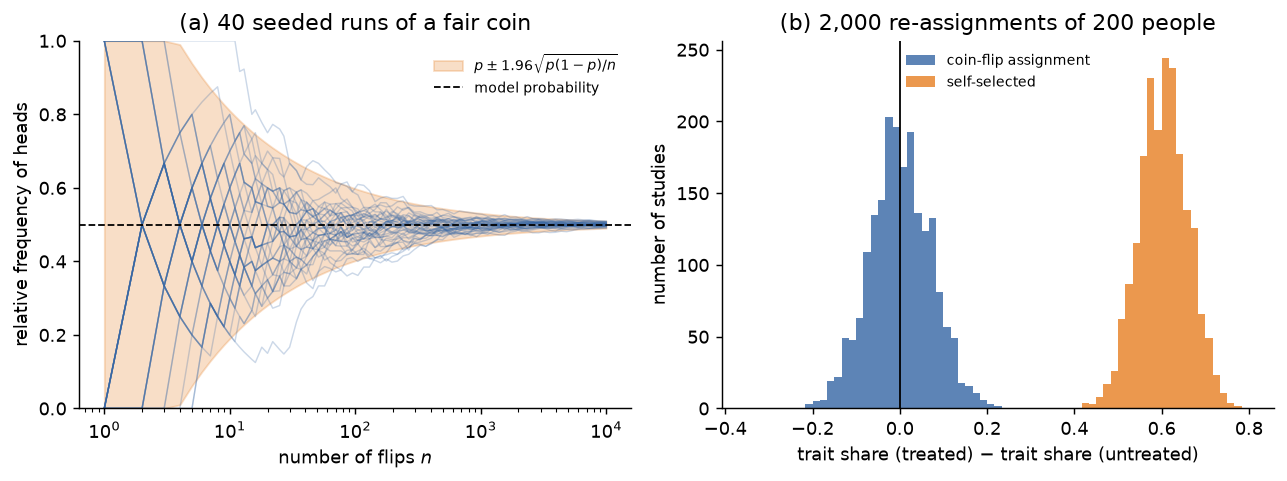

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for k in range(len(seeds)):
    ax[0].plot(grid, paths[k], color="#3465a4", alpha=0.25, lw=0.8)
ax[0].fill_between(grid, (P - half).clip(0, 1), (P + half).clip(0, 1), color="#e67e22", alpha=0.25,
                   label=r"$p \pm 1.96\sqrt{p(1-p)/n}$")
ax[0].axhline(P, color="k", ls="--", lw=1, label="model probability")
ax[0].set(xscale="log", xlabel="number of flips $n$", ylabel="relative frequency of heads",
          ylim=(0, 1), title="(a) 40 seeded runs of a fair coin")
ax[0].legend(frameon=False, loc="upper right", fontsize=8)
bins = np.linspace(-0.35, 0.8, 70)
ax[1].hist(imb_rand, bins=bins, color="#3465a4", alpha=0.8, label="coin-flip assignment")
ax[1].hist(imb_self, bins=bins, color="#e67e22", alpha=0.8, label="self-selected")
ax[1].axvline(0, color="k", lw=1)
ax[1].set(xlabel="trait share (treated) − trait share (untreated)", ylabel="number of studies",
          title="(b) 2,000 re-assignments of 200 people")
ax[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Explain.** Coin-flip assignment centers the imbalance at zero. But a single small study can still be unlucky. The printed share of studies with a gap above 0.10 is not zero. That is why reports give group sizes and uncertainty. Self-selection shifts the whole distribution away from zero. More data cannot fix that.

## Going deeper

### Law of large numbers

Take independent trials $X_i\sim\mathrm{Bernoulli}(p)$ with $\hat p_n=\frac1n\sum_{i=1}^n X_i$. Then

$$\mathbb E[\hat p_n]=p,\qquad \operatorname{Var}(\hat p_n)=\frac{p(1-p)}{n},\qquad
P\big(|\hat p_n-p|\ge\varepsilon\big)\le\frac{p(1-p)}{n\varepsilon^2}\ (\text{Chebyshev}).$$

The central limit theorem gives the approximate pointwise band $p\pm1.96\sqrt{p(1-p)/n}$ for a fixed $n$. A band that holds for the *whole path* at once must be wider. Such a band can come, for example, from the law of the iterated logarithm or from a union bound.

### Randomization

Write $Y^t$ for the potential outcome under treatment $t$. In the model of Section 3,

$$\mathbb E[Y\mid T=1]-\mathbb E[Y\mid T=0]
=\underbrace{0.1}_{\text{effect}}+0.4\,\big(P(U=1\mid T=1)-P(U=1\mid T=0)\big).$$

Random assignment makes $T$ independent of $U$ (and so of $(Y^0,Y^1)$). This is called *exchangeability*. The second term then vanishes in expectation [@hernan]. Let the self-selection strength be $s$. Then $P(U=1\mid T=1)-P(U=1\mid T=0)=2s$ when $P(U=1)=\tfrac12$, so the bias is $0.8\,s$.

## Exercises

:::{admonition} Exercise: :label: lab1-ex1
:class: tip
For a fair die and the event "six", compute the half-width of the pointwise 95 % band after $n=6000$ rolls.
:::

:::{dropdown} Solution
$1.96\sqrt{(1/6)(5/6)/6000}\approx 0.0094$. The check cell below computes it.
:::

:::{admonition} Exercise: :label: lab1-ex2
:class: tip
Use the 40 seeded runs of 10,000 flips. Look at every flip that comes right after five heads in a row. What fraction of those flips are heads? What does the independent-trials model predict?
:::

:::{dropdown} Solution
The model predicts one half, because each flip is independent of the past. The check cell rebuilds the single flips from the running count. It confirms that the measured fraction is close to one half (within 0.03). Past heads do not make a tail "due".
:::

:::{admonition} Exercise: :label: lab1-ex3
:class: tip
Use `s.causal(prevalence=0.5, low=0.2, high=0.8, base=0.2, effect=0.1, confound=0.4)`. What is the bias of the simple contrast? How does it match the formula in *Going deeper*?
:::

:::{dropdown} Solution
`observed − ate` $=0.34-0.10=0.24$. Here $s=0.3$, and $0.8\times0.3=0.24$.
:::

## Check yourself

In [14]:
# Exercise 1
hw = 1.96 * math.sqrt((1 / 6) * (5 / 6) / 6000)
assert abs(hw - 0.0094) < 1e-4

# Exercise 2: rebuild individual flips from the running frequency, pooled over the 40 seeded runs
def flips_of(run):
    hits = np.rint(np.asarray(run["trace"]) * np.arange(1, run["n"] + 1)).astype(int)
    f = np.diff(np.concatenate([[0], hits]))
    assert set(np.unique(f)) <= {0, 1} and f.sum() == run["hits"]
    return f

after5 = []
for sd in seeds:
    f = flips_of(s.trials(0.5, 10000, seed=sd))
    w = np.convolve(f, np.ones(5, dtype=int), "valid")[:-1]      # heads among flips i-5 ... i-1
    after5.extend(f[5:][w == 5])
print(f"flips right after five heads: {len(after5)}, fraction heads: {np.mean(after5):.3f}")
assert len(after5) > 5000 and abs(np.mean(after5) - 0.5) < 0.03

# Exercise 3 and the bias formula bias = 0.8 * s
c = s.causal(prevalence=0.5, low=0.2, high=0.8, base=0.2, effect=0.1, confound=0.4)
assert math.isclose(c["observed"] - c["ate"], 0.24)
for st in strengths:
    assert math.isclose(res[st]["theory"] - TRUE_EFFECT, 0.8 * st, abs_tol=1e-12)
print("All checks passed.")

flips right after five heads: 12394, fraction heads: 0.500
All checks passed.


:::{note} Limits of this model
- Seeded pseudo-random numbers (a linear congruential generator in `science.trials`) imitate independent trials. They are not physical randomness, and real trials can be dependent.
- The 95 % band uses a normal approximation and is pointwise. It is not a band for a whole run, and it is poor for very small $n$.
- Randomization balances hidden traits only on average. It does not fix non-compliance, missing outcomes, or a badly defined comparison.
- The outcome model is linear in probabilities, with no interaction between treatment and trait. Real effects can differ across people.
:::